In [ ]:
!pip install pandas flask requests

In [ ]:
import pandas as pd
import requests
import json

print("Libraries loaded successfully")


Libraries loaded successfully


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving AI_Tax_Auditor_Large_Datasets.zip to AI_Tax_Auditor_Large_Datasets.zip


In [ ]:
import zipfile

with zipfile.ZipFile("AI_Tax_Auditor_Large_Datasets.zip", "r") as zip_ref:
    zip_ref.extractall("datasets")

print("Datasets extracted successfully!")

Datasets extracted successfully!


In [ ]:
import pandas as pd

In [ ]:
products = pd.read_csv("datasets/products.csv")
taxes = pd.read_csv("datasets/taxes.csv")
policies = pd.read_csv("datasets/trade_policies.csv")
transactions = pd.read_csv("datasets/sample_transactions.csv")

In [ ]:
print("Products:", len(products))
print("Countries:", len(taxes))
print("Policies:", len(policies))
print("Transactions:", len(transactions))

Products: 1200
Countries: 40
Policies: 240
Transactions: 400


In [ ]:
products.head()

,Product_ID,Product,HS_Code,Category,Unit
0,1,Laptop Standard,847130,Electronics,Piece
1,2,Laptop Basic,847130,Electronics,Piece
2,3,Laptop Premium,847130,Electronics,Piece
3,4,Laptop Pro,847130,Electronics,Piece
4,5,Laptop Advanced,847130,Electronics,Piece


In [ ]:
taxes.head()


,Country,Currency,GST_VAT_Percent,Default_Import_Duty_Percent
0,India,INR,18.0,10
1,United States,USD,0.0,5
2,Germany,EUR,19.0,8
3,United Arab Emirates,AED,5.0,5
4,Japan,JPY,10.0,6


In [ ]:
policies.head()

,Policy_ID,Country,Category,Policy_Summary,Compliance_Note,Source_Type
0,POL0001,India,Electronics,Customs documentation and applicable import re...,"Verify HS classification, origin, tariff treat...",Prototype policy record for academic system te...
1,POL0002,India,Computer Accessories,Customs documentation and applicable import re...,"Verify HS classification, origin, tariff treat...",Prototype policy record for academic system te...
2,POL0003,India,Home Appliances,Customs documentation and applicable import re...,"Verify HS classification, origin, tariff treat...",Prototype policy record for academic system te...
3,POL0004,India,Automotive,Customs documentation and applicable import re...,"Verify HS classification, origin, tariff treat...",Prototype policy record for academic system te...
4,POL0005,India,Medical Supplies,Customs documentation and applicable import re...,"Verify HS classification, origin, tariff treat...",Prototype policy record for academic system te...


In [ ]:
transactions.head()

,Transaction_ID,Product,HS_Code,Origin_Country,Destination_Country,Unit_Price_USD,Quantity,Shipping_USD
0,1,Laptop Standard,847130,India,France,87.25,2,38.5
1,2,Laptop Basic,847130,United States,Italy,124.50,3,57.0
2,3,Laptop Premium,847130,Germany,Spain,161.75,4,75.5
3,4,Laptop Pro,847130,United Arab Emirates,Singapore,199.00,5,94.0
4,5,Laptop Advanced,847130,Japan,Malaysia,236.25,6,112.5


In [ ]:
def find_product(product_name):
    result = products[
        products["Product"].str.contains(product_name, case=False, na=False)
    ]

    if len(result) == 0:
        print("Product not found")
    else:
        print(result[["Product", "HS_Code", "Category"]].head(10))

In [ ]:
find_product("Laptop")

           Product  HS_Code     Category
0  Laptop Standard   847130  Electronics
1     Laptop Basic   847130  Electronics
2   Laptop Premium   847130  Electronics
3       Laptop Pro   847130  Electronics
4  Laptop Advanced   847130  Electronics
5      Laptop Lite   847130  Electronics
6      Laptop Plus   847130  Electronics
7       Laptop Max   847130  Electronics
8      Laptop Mini   847130  Electronics
9     Laptop Ultra   847130  Electronics


In [ ]:
find_product("Keyboard")

               Product  HS_Code              Category
140  Keyboard Standard   847160  Computer Accessories
141     Keyboard Basic   847160  Computer Accessories
142   Keyboard Premium   847160  Computer Accessories
143       Keyboard Pro   847160  Computer Accessories
144  Keyboard Advanced   847160  Computer Accessories
145      Keyboard Lite   847160  Computer Accessories
146      Keyboard Plus   847160  Computer Accessories
147       Keyboard Max   847160  Computer Accessories
148      Keyboard Mini   847160  Computer Accessories
149     Keyboard Ultra   847160  Computer Accessories


In [ ]:
def calculate_landing_cost(product_name, destination, price, quantity, shipping):

    # Find product
    product = products[
        products["Product"].str.contains(product_name, case=False, na=False)
    ]

    if product.empty:
        print("Product not found")
        return

    # Get first matching product
    product = product.iloc[0]

    # Find destination tax
    tax = taxes[
        taxes["Country"].str.lower() == destination.lower()
    ]

    if tax.empty:
        print("Country not found")
        return

    tax = tax.iloc[0]

    # Calculate values
    product_cost = price * quantity
    customs_value = product_cost + shipping

    duty_rate = tax["Default_Import_Duty_Percent"]
    gst_rate = tax["GST_VAT_Percent"]

    customs_duty = customs_value * duty_rate / 100
    taxable_value = customs_value + customs_duty
    gst = taxable_value * gst_rate / 100

    landing_cost = taxable_value + gst

    # Display result
    print("----- LANDING COST RESULT -----")
    print("Product:", product["Product"])
    print("HS Code:", product["HS_Code"])
    print("Category:", product["Category"])
    print("Destination:", tax["Country"])
    print()
    print("Product Cost: $", round(product_cost, 2))
    print("Shipping: $", round(shipping, 2))
    print("Customs Duty: $", round(customs_duty, 2))
    print("GST/VAT: $", round(gst, 2))
    print("-------------------------------")
    print("TOTAL LANDING COST: $", round(landing_cost, 2))

In [ ]:
calculate_landing_cost(
    "Laptop",
    "India",
    800,
    2,
    100
)

----- LANDING COST RESULT -----
Product: Laptop Standard
HS Code: 847130
Category: Electronics
Destination: India

Product Cost: $ 1600
Shipping: $ 100
Customs Duty: $ 170.0
GST/VAT: $ 336.6
-------------------------------
TOTAL LANDING COST: $ 2206.6


In [ ]:
product_name = input("Enter product name: ")
destination = input("Enter destination country: ")
price = float(input("Enter price per unit in USD: "))
quantity = int(input("Enter quantity: "))
shipping = float(input("Enter shipping cost in USD: "))

calculate_landing_cost(
    product_name,
    destination,
    price,
    quantity,
    shipping
)

Enter product name: laptop
Enter destination country: india
Enter price per unit in USD: 450
Enter quantity: 2
Enter shipping cost in USD: 70
----- LANDING COST RESULT -----
Product: Laptop Standard
HS Code: 847130
Category: Electronics
Destination: India

Product Cost: $ 900.0
Shipping: $ 70.0
Customs Duty: $ 97.0
GST/VAT: $ 192.06
-------------------------------
TOTAL LANDING COST: $ 1259.06


In [ ]:
def find_policy(product_name, destination):

    # Find product
    product = products[
        products["Product"].str.contains(product_name, case=False, na=False)
    ]

    if product.empty:
        print("Product not found")
        return

    category = product.iloc[0]["Category"]

    # Find policy
    policy = policies[
        (policies["Country"].str.lower() == destination.lower()) &
        (policies["Category"].str.lower() == category.lower())
    ]

    if policy.empty:
        print("Policy not found")
        return

    policy = policy.iloc[0]

    print("----- TRADE POLICY -----")
    print("Country:", policy["Country"])
    print("Category:", policy["Category"])
    print("Policy:", policy["Policy_Summary"])
    print("Compliance:", policy["Compliance_Note"])

In [ ]:
find_policy("Laptop", "India")

----- TRADE POLICY -----
Country: India
Category: Electronics
Policy: Customs documentation and applicable import requirements apply.
Compliance: Verify HS classification, origin, tariff treatment, exemptions and current requirements.


In [ ]:
def calculate_landing_cost(product_name, destination, price, quantity, shipping):

    # Find product
    product = products[
        products["Product"].str.contains(product_name, case=False, na=False)
    ]

    if product.empty:
        print("Product not found")
        return

    product = product.iloc[0]

    # Find tax information
    tax = taxes[
        taxes["Country"].str.lower() == destination.lower()
    ]

    if tax.empty:
        print("Country not found")
        return

    tax = tax.iloc[0]

    # Calculate product cost
    product_cost = price * quantity

    # Customs value
    customs_value = product_cost + shipping

    # Customs duty
    duty = customs_value * tax["Default_Import_Duty_Percent"] / 100

    # Taxable value
    taxable_value = customs_value + duty

    # GST/VAT
    gst_vat = taxable_value * tax["GST_VAT_Percent"] / 100

    # Final landing cost
    landing_cost = taxable_value + gst_vat

    print("========== LANDING COST ==========")
    print("Product       :", product["Product"])
    print("HS Code       :", product["HS_Code"])
    print("Category      :", product["Category"])
    print("Destination   :", tax["Country"])
    print("----------------------------------")
    print("Product Cost  : $", round(product_cost, 2))
    print("Shipping Cost : $", round(shipping, 2))
    print("Customs Duty  : $", round(duty, 2))
    print("GST/VAT       : $", round(gst_vat, 2))
    print("----------------------------------")
    print("TOTAL COST    : $", round(landing_cost, 2))
    print("==================================")

In [ ]:
calculate_landing_cost(
    "Laptop",
    "India",
    800,
    2,
    100
)

========== LANDING COST ==========
Product       : Laptop Standard
HS Code       : 847130
Category      : Electronics
Destination   : India
----------------------------------
Product Cost  : $ 1600
Shipping Cost : $ 100
Customs Duty  : $ 170.0
GST/VAT       : $ 336.6
----------------------------------
TOTAL COST    : $ 2206.6


In [ ]:
def tax_auditor(product_name, destination, price, quantity, shipping):

    # 1. Find product
    product = products[
        products["Product"].str.contains(product_name, case=False, na=False)
    ]

    if product.empty:
        print("Product not found")
        return

    product = product.iloc[0]

    # 2. Find country tax
    tax = taxes[
        taxes["Country"].str.lower() == destination.lower()
    ]

    if tax.empty:
        print("Country not found")
        return

    tax = tax.iloc[0]

    # 3. Find policy
    policy = policies[
        (policies["Country"].str.lower() == destination.lower()) &
        (policies["Category"].str.lower() == product["Category"].lower())
    ]

    # 4. Calculate cost
    product_cost = price * quantity
    customs_value = product_cost + shipping

    duty = customs_value * tax["Default_Import_Duty_Percent"] / 100

    taxable_value = customs_value + duty

    gst_vat = taxable_value * tax["GST_VAT_Percent"] / 100

    landing_cost = taxable_value + gst_vat

    # 5. Display complete report
    print("\n========================================")
    print("       LIVE POLICY & TAX AUDITOR")
    print("========================================")

    print("\nPRODUCT INFORMATION")
    print("-------------------")
    print("Product       :", product["Product"])
    print("HS Code       :", product["HS_Code"])
    print("Category      :", product["Category"])

    print("\nTRADE INFORMATION")
    print("-----------------")
    print("Destination   :", tax["Country"])
    print("Currency      :", tax["Currency"])

    print("\nTAX INFORMATION")
    print("----------------")
    print("Import Duty   :", tax["Default_Import_Duty_Percent"], "%")
    print("GST/VAT       :", tax["GST_VAT_Percent"], "%")

    print("\nPOLICY INFORMATION")
    print("-------------------")

    if not policy.empty:
        policy = policy.iloc[0]

        print("Policy        :", policy["Policy_Summary"])
        print("Compliance    :", policy["Compliance_Note"])
    else:
        print("Policy not found")

    print("\nLANDING COST")
    print("------------")
    print("Product Cost  : $", round(product_cost, 2))
    print("Shipping      : $", round(shipping, 2))
    print("Customs Duty  : $", round(duty, 2))
    print("GST/VAT       : $", round(gst_vat, 2))

    print("----------------------------------------")
    print("FINAL LANDING COST : $", round(landing_cost, 2))
    print("========================================")

In [ ]:
tax_auditor(
    "Laptop",
    "India",
    800,
    2,
    100
)


       LIVE POLICY & TAX AUDITOR

PRODUCT INFORMATION
-------------------
Product       : Laptop Standard
HS Code       : 847130
Category      : Electronics

TRADE INFORMATION
-----------------
Destination   : India
Currency      : INR

TAX INFORMATION
----------------
Import Duty   : 10 %
GST/VAT       : 18.0 %

POLICY INFORMATION
-------------------
Policy        : Customs documentation and applicable import requirements apply.
Compliance    : Verify HS classification, origin, tariff treatment, exemptions and current requirements.

LANDING COST
------------
Product Cost  : $ 1600
Shipping      : $ 100
Customs Duty  : $ 170.0
GST/VAT       : $ 336.6
----------------------------------------
FINAL LANDING COST : $ 2206.6


In [ ]:
tax_auditor(
    "Keyboard",
    "Japan",
    50,
    10,
    80
)


       LIVE POLICY & TAX AUDITOR

PRODUCT INFORMATION
-------------------
Product       : Keyboard Standard
HS Code       : 847160
Category      : Computer Accessories

TRADE INFORMATION
-----------------
Destination   : Japan
Currency      : JPY

TAX INFORMATION
----------------
Import Duty   : 6 %
GST/VAT       : 10.0 %

POLICY INFORMATION
-------------------
Policy        : Customs documentation and applicable import requirements apply.
Compliance    : Verify HS classification, origin, tariff treatment, exemptions and current requirements.

LANDING COST
------------
Product Cost  : $ 500
Shipping      : $ 80
Customs Duty  : $ 34.8
GST/VAT       : $ 61.48
----------------------------------------
FINAL LANDING COST : $ 676.28


In [ ]:
tax_auditor(
    "Laptop",
    "XYZ Country",
    500,
    2,
    100
)

Country not found


In [ ]:
def input_agent(product_name, destination, price, quantity, shipping):

    data = {
        "product_name": product_name,
        "destination": destination,
        "price": price,
        "quantity": quantity,
        "shipping": shipping
    }

    return data

In [ ]:
def product_agent(data):

    product = products[
        products["Product"].str.contains(
            data["product_name"],
            case=False,
            na=False
        )
    ]

    if product.empty:
        return None

    product = product.iloc[0]

    data["product"] = product["Product"]
    data["hs_code"] = product["HS_Code"]
    data["category"] = product["Category"]

    return data

In [ ]:
def policy_agent(data):

    policy = policies[
        (policies["Country"].str.lower() == data["destination"].lower()) &
        (policies["Category"].str.lower() == data["category"].lower())
    ]

    if policy.empty:
        data["policy"] = "Policy not found"
        data["compliance"] = "No policy information available"
        return data

    policy = policy.iloc[0]

    data["policy"] = policy["Policy_Summary"]
    data["compliance"] = policy["Compliance_Note"]

    return data

In [ ]:
def tax_agent(data):

    tax = taxes[
        taxes["Country"].str.lower() == data["destination"].lower()
    ]

    if tax.empty:
        return None

    tax = tax.iloc[0]

    data["currency"] = tax["Currency"]
    data["duty_rate"] = tax["Default_Import_Duty_Percent"]
    data["gst_rate"] = tax["GST_VAT_Percent"]

    return data

In [ ]:
def calculation_agent(data):

    product_cost = data["price"] * data["quantity"]

    customs_value = product_cost + data["shipping"]

    customs_duty = (
        customs_value * data["duty_rate"] / 100
    )

    taxable_value = customs_value + customs_duty

    gst_vat = (
        taxable_value * data["gst_rate"] / 100
    )

    landing_cost = taxable_value + gst_vat

    data["product_cost"] = product_cost
    data["customs_value"] = customs_value
    data["customs_duty"] = customs_duty
    data["gst_vat"] = gst_vat
    data["landing_cost"] = landing_cost

    return data

In [ ]:
def report_agent(data):

    print("\n")
    print("=" * 50)
    print("        LIVE POLICY & TAX AUDITOR")
    print("=" * 50)

    print("\nPRODUCT INFORMATION")
    print("-" * 25)
    print("Product      :", data["product"])
    print("HS Code      :", data["hs_code"])
    print("Category     :", data["category"])

    print("\nTRADE INFORMATION")
    print("-" * 25)
    print("Destination  :", data["destination"])
    print("Currency     :", data["currency"])

    print("\nTAX INFORMATION")
    print("-" * 25)
    print("Import Duty  :", data["duty_rate"], "%")
    print("GST/VAT      :", data["gst_rate"], "%")

    print("\nPOLICY INFORMATION")
    print("-" * 25)
    print("Policy       :", data["policy"])
    print("Compliance   :", data["compliance"])

    print("\nCOST CALCULATION")
    print("-" * 25)
    print("Product Cost :", round(data["product_cost"], 2))
    print("Shipping     :", round(data["shipping"], 2))
    print("Customs Duty :", round(data["customs_duty"], 2))
    print("GST/VAT      :", round(data["gst_vat"], 2))

    print("\n" + "=" * 50)
    print("FINAL LANDING COST : $", round(data["landing_cost"], 2))
    print("=" * 50)

In [ ]:
def run_auditor(product_name, destination, price, quantity, shipping):

    # Input Agent
    data = input_agent(
        product_name,
        destination,
        price,
        quantity,
        shipping
    )

    # Product Agent
    data = product_agent(data)

    if data is None:
        print("Product not found")
        return

    # Policy Agent
    data = policy_agent(data)

    # Tax Agent
    data = tax_agent(data)

    if data is None:
        print("Country not found")
        return

    # Calculation Agent
    data = calculation_agent(data)

    # Report Agent
    report_agent(data)

In [ ]:
run_auditor(
    "Laptop",
    "India",
    800,
    2,
    100
)



        LIVE POLICY & TAX AUDITOR

PRODUCT INFORMATION
-------------------------
Product      : Laptop Standard
HS Code      : 847130
Category     : Electronics

TRADE INFORMATION
-------------------------
Destination  : India
Currency     : INR

TAX INFORMATION
-------------------------
Import Duty  : 10 %
GST/VAT      : 18.0 %

POLICY INFORMATION
-------------------------
Policy       : Customs documentation and applicable import requirements apply.
Compliance   : Verify HS classification, origin, tariff treatment, exemptions and current requirements.

COST CALCULATION
-------------------------
Product Cost : 1600
Shipping     : 100
Customs Duty : 170.0
GST/VAT      : 336.6

FINAL LANDING COST : $ 2206.6


In [ ]:
data = input_agent(
    "Laptop",
    "India",
    800,
    2,
    100
)

data = product_agent(data)

if data is None:
    print("Product not found")
else:
    data = policy_agent(data)
    data = tax_agent(data)

    if data is None:
        print("Country not found")
    else:
        data = calculation_agent(data)
        report_agent(data)



        LIVE POLICY & TAX AUDITOR

PRODUCT INFORMATION
-------------------------
Product      : Laptop Standard
HS Code      : 847130
Category     : Electronics

TRADE INFORMATION
-------------------------
Destination  : India
Currency     : INR

TAX INFORMATION
-------------------------
Import Duty  : 10 %
GST/VAT      : 18.0 %

POLICY INFORMATION
-------------------------
Policy       : Customs documentation and applicable import requirements apply.
Compliance   : Verify HS classification, origin, tariff treatment, exemptions and current requirements.

COST CALCULATION
-------------------------
Product Cost : 1600
Shipping     : 100
Customs Duty : 170.0
GST/VAT      : 336.6

FINAL LANDING COST : $ 2206.6


In [ ]:
!pip install -q chromadb sentence-transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 733.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 45.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 62.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 42.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.6/204.6 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 5.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently

In [ ]:
import chromadb
from sentence_transformers import SentenceTransformer

print("RAG libraries loaded successfully!")

RAG libraries loaded successfully!


In [ ]:
model = SentenceTransformer("all-MiniLM-L6-v2")

print("Embedding model loaded!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded!


In [ ]:
client = chromadb.Client()

collection = client.get_or_create_collection(
    name="trade_policies"
)

print("ChromaDB collection created!")

ChromaDB collection created!


In [ ]:
documents = []
ids = []

for i, row in policies.iterrows():

    text = f"""
Country: {row['Country']}
Category: {row['Category']}
Policy: {row['Policy_Summary']}
Compliance: {row['Compliance_Note']}
"""

    documents.append(text)
    ids.append(str(row["Policy_ID"]))

print("Policy documents:", len(documents))

Policy documents: 240


In [ ]:
embeddings = model.encode(documents).tolist()

print("Embeddings created:", len(embeddings))

Embeddings created: 240


In [ ]:
collection.add(
    ids=ids,
    documents=documents,
    embeddings=embeddings
)

print("240 policies stored in ChromaDB!")

240 policies stored in ChromaDB!


In [ ]:
query = "India electronics import policy"

query_embedding = model.encode([query]).tolist()

results = collection.query(
    query_embeddings=query_embedding,
    n_results=3
)

for document in results["documents"][0]:
    print(document)
    print("-" * 50)


Country: India
Category: Electronics
Policy: Customs documentation and applicable import requirements apply.
Compliance: Verify HS classification, origin, tariff treatment, exemptions and current requirements.

--------------------------------------------------

Country: India
Category: Computer Accessories
Policy: Customs documentation and applicable import requirements apply.
Compliance: Verify HS classification, origin, tariff treatment, exemptions and current requirements.

--------------------------------------------------

Country: India
Category: Automotive
Policy: Customs documentation and applicable import requirements apply.
Compliance: Verify HS classification, origin, tariff treatment, exemptions and current requirements.

--------------------------------------------------


In [ ]:
def retrieve_policy(query, n_results=3):

    query_embedding = model.encode([query]).tolist()

    results = collection.query(
        query_embeddings=query_embedding,
        n_results=n_results
    )

    return results["documents"][0]

In [ ]:
results = retrieve_policy(
    "India electronics import requirements"
)

for result in results:
    print(result)
    print("-" * 50)


Country: India
Category: Electronics
Policy: Customs documentation and applicable import requirements apply.
Compliance: Verify HS classification, origin, tariff treatment, exemptions and current requirements.

--------------------------------------------------

Country: India
Category: Computer Accessories
Policy: Customs documentation and applicable import requirements apply.
Compliance: Verify HS classification, origin, tariff treatment, exemptions and current requirements.

--------------------------------------------------

Country: India
Category: Automotive
Policy: Customs documentation and applicable import requirements apply.
Compliance: Verify HS classification, origin, tariff treatment, exemptions and current requirements.

--------------------------------------------------


In [ ]:
def rag_policy_agent(data):

    query = (
        data["destination"]
        + " "
        + data["category"]
        + " import policy and compliance requirements"
    )

    results = retrieve_policy(query, 1)

    if results:
        data["rag_policy"] = results[0]
    else:
        data["rag_policy"] = "No relevant policy found"

    return data

In [ ]:
data = input_agent(
    "Laptop",
    "India",
    800,
    2,
    100
)

data = product_agent(data)

data = rag_policy_agent(data)

print(data["rag_policy"])


Country: India
Category: Electronics
Policy: Customs documentation and applicable import requirements apply.
Compliance: Verify HS classification, origin, tariff treatment, exemptions and current requirements.



In [ ]:
def run_auditor_rag(product_name, destination, price, quantity, shipping):

    # Input Agent
    data = input_agent(
        product_name,
        destination,
        price,
        quantity,
        shipping
    )

    # Product Agent
    data = product_agent(data)

    if data is None:
        print("Product not found")
        return

    # RAG Policy Agent
    data = rag_policy_agent(data)

    # Tax Agent
    data = tax_agent(data)

    if data is None:
        print("Country not found")
        return

    # Calculation Agent
    data = calculation_agent(data)

    # Report
    report_agent(data)

In [ ]:
def rag_report_agent(data):

    print("\n========================================")
    print("       LIVE POLICY & TAX AUDITOR")
    print("========================================")

    print("\nPRODUCT INFORMATION")
    print("-------------------")
    print("Product      :", data["product"])
    print("HS Code      :", data["hs_code"])
    print("Category     :", data["category"])

    print("\nTRADE INFORMATION")
    print("-----------------")
    print("Destination  :", data["destination"])
    print("Currency     :", data["currency"])

    print("\nTAX INFORMATION")
    print("----------------")
    print("Import Duty  :", data["duty_rate"], "%")
    print("GST/VAT      :", data["gst_rate"], "%")

    print("\nRAG POLICY RESULT")
    print("-----------------")
    print(data["rag_policy"])

    print("\nCOST CALCULATION")
    print("----------------")
    print("Product Cost :", round(data["product_cost"], 2))
    print("Shipping     :", round(data["shipping"], 2))
    print("Customs Duty :", round(data["customs_duty"], 2))
    print("GST/VAT      :", round(data["gst_vat"], 2))

    print("----------------------------------------")
    print("FINAL LANDING COST : $",
          round(data["landing_cost"], 2))
    print("========================================")

In [ ]:
def run_auditor_rag(product_name, destination, price, quantity, shipping):

    data = input_agent(
        product_name,
        destination,
        price,
        quantity,
        shipping
    )

    data = product_agent(data)

    if data is None:
        print("Product not found")
        return

    data = rag_policy_agent(data)

    data = tax_agent(data)

    if data is None:
        print("Country not found")
        return

    data = calculation_agent(data)

    rag_report_agent(data)

In [ ]:
run_auditor_rag(
    "Laptop",
    "India",
    800,
    2,
    100
)


       LIVE POLICY & TAX AUDITOR

PRODUCT INFORMATION
-------------------
Product      : Laptop Standard
HS Code      : 847130
Category     : Electronics

TRADE INFORMATION
-----------------
Destination  : India
Currency     : INR

TAX INFORMATION
----------------
Import Duty  : 10 %
GST/VAT      : 18.0 %

RAG POLICY RESULT
-----------------

Country: India
Category: Electronics
Policy: Customs documentation and applicable import requirements apply.
Compliance: Verify HS classification, origin, tariff treatment, exemptions and current requirements.


COST CALCULATION
----------------
Product Cost : 1600
Shipping     : 100
Customs Duty : 170.0
GST/VAT      : 336.6
----------------------------------------
FINAL LANDING COST : $ 2206.6


In [ ]:
def rag_report_agent(data):

    print("\n========================================")
    print("       LIVE POLICY & TAX AUDITOR")
    print("========================================")

    print("\nPRODUCT INFORMATION")
    print("-------------------")
    print("Product      :", data["product"])
    print("HS Code      :", data["hs_code"])
    print("Category     :", data["category"])

    print("\nTRADE INFORMATION")
    print("-----------------")
    print("Destination  :", data["destination"])
    print("Currency     :", data["currency"])

    print("\nTAX INFORMATION")
    print("----------------")
    print("Import Duty  :", data["duty_rate"], "%")
    print("GST/VAT      :", data["gst_rate"], "%")

    print("\nRAG POLICY RESULT")
    print("-----------------")
    print(data["rag_policy"])

    print("\nCOST CALCULATION")
    print("----------------")
    print("Product Cost :", round(data["product_cost"], 2))
    print("Shipping     :", round(data["shipping"], 2))
    print("Customs Duty :", round(data["customs_duty"], 2))
    print("GST/VAT      :", round(data["gst_vat"], 2))

    print("----------------------------------------")
    print("FINAL LANDING COST : $",
          round(data["landing_cost"], 2))
    print("========================================")

In [ ]:
def run_auditor_rag(product_name, destination, price, quantity, shipping):

    # Input Agent
    data = input_agent(
        product_name,
        destination,
        price,
        quantity,
        shipping
    )

    # Product Agent
    data = product_agent(data)

    if data is None:
        print("Product not found")
        return

    # RAG Policy Agent
    data = rag_policy_agent(data)

    # Tax Agent
    data = tax_agent(data)

    if data is None:
        print("Country not found")
        return

    # Calculation Agent
    data = calculation_agent(data)

    # RAG Report Agent
    rag_report_agent(data)

In [ ]:
run_auditor_rag(
    "Laptop",
    "India",
    800,
    2,
    100
)


       LIVE POLICY & TAX AUDITOR

PRODUCT INFORMATION
-------------------
Product      : Laptop Standard
HS Code      : 847130
Category     : Electronics

TRADE INFORMATION
-----------------
Destination  : India
Currency     : INR

TAX INFORMATION
----------------
Import Duty  : 10 %
GST/VAT      : 18.0 %

RAG POLICY RESULT
-----------------

Country: India
Category: Electronics
Policy: Customs documentation and applicable import requirements apply.
Compliance: Verify HS classification, origin, tariff treatment, exemptions and current requirements.


COST CALCULATION
----------------
Product Cost : 1600
Shipping     : 100
Customs Duty : 170.0
GST/VAT      : 336.6
----------------------------------------
FINAL LANDING COST : $ 2206.6


In [ ]:
def run_agentic_auditor(product_name, destination, price, quantity, shipping):

    print("\n" + "=" * 60)
    print("           AGENTIC POLICY & TAX AUDITOR")
    print("=" * 60)

    # ---------------- INPUT AGENT ----------------
    print("\n[1] INPUT AGENT")
    print("-" * 60)

    data = input_agent(
        product_name,
        destination,
        price,
        quantity,
        shipping
    )

    print("✓ Product received   :", product_name)
    print("✓ Destination        :", destination)
    print("✓ Quantity            :", quantity)
    print("✓ Input validated")

    # ---------------- PRODUCT AGENT ----------------
    print("\n[2] PRODUCT AGENT")
    print("-" * 60)

    data = product_agent(data)

    if data is None:
        print("✗ Product not found")
        return

    print("✓ Product identified :", data["product"])
    print("✓ HS Code            :", data["hs_code"])
    print("✓ Category           :", data["category"])

    # ---------------- RAG POLICY AGENT ----------------
    print("\n[3] RAG POLICY AGENT")
    print("-" * 60)

    query = (
        data["destination"]
        + " "
        + data["category"]
        + " import policy and compliance requirements"
    )

    print("Query:", query)
    print("✓ Converting query into embedding")

    results = retrieve_policy(query, 3)

    print("✓ ChromaDB searched")
    print("✓ Relevant policy documents retrieved:", len(results))

    if results:
        data["rag_policy"] = results[0]

        print("\nTOP RETRIEVED POLICY")
        print("-" * 40)
        print(data["rag_policy"])
    else:
        data["rag_policy"] = "No relevant policy found"
        print("✗ No policy found")

    # ---------------- TAX AGENT ----------------
    print("\n[4] TAX AGENT")
    print("-" * 60)

    data = tax_agent(data)

    if data is None:
        print("✗ Country not found")
        return

    print("✓ Country matched    :", data["destination"])
    print("✓ Import Duty        :", data["duty_rate"], "%")
    print("✓ GST/VAT            :", data["gst_rate"], "%")

    # ---------------- CALCULATION AGENT ----------------
    print("\n[5] CALCULATION AGENT")
    print("-" * 60)

    data = calculation_agent(data)

    print("✓ Product Cost       : $", round(data["product_cost"], 2))
    print("✓ Shipping Cost      : $", round(data["shipping"], 2))
    print("✓ Customs Value      : $", round(data["customs_value"], 2))
    print("✓ Customs Duty       : $", round(data["customs_duty"], 2))
    print("✓ Taxable Value      : $", round(
        data["customs_value"] + data["customs_duty"], 2
    ))
    print("✓ GST/VAT            : $", round(data["gst_vat"], 2))

    # ---------------- FINAL RESULT ----------------
    print("\n[6] REPORT AGENT")
    print("-" * 60)

    print("✓ All agents completed")
    print("✓ Audit report generated")

    print("\n" + "=" * 60)
    print("              FINAL AUDIT RESULT")
    print("=" * 60)

    print("Product             :", data["product"])
    print("HS Code             :", data["hs_code"])
    print("Destination         :", data["destination"])
    print("Import Duty         :", data["duty_rate"], "%")
    print("GST/VAT             :", data["gst_rate"], "%")

    print("-" * 60)

    print("FINAL LANDING COST  : $", round(data["landing_cost"], 2))

    print("=" * 60)
    print("Agents Executed     : 6")
    print("RAG Status          : SUCCESS")
    print("=" * 60)

In [ ]:
run_agentic_auditor(
    "Laptop",
    "India",
    800,
    2,
    100
)


           AGENTIC POLICY & TAX AUDITOR

[1] INPUT AGENT
------------------------------------------------------------
✓ Product received   : Laptop
✓ Destination        : India
✓ Quantity            : 2
✓ Input validated

[2] PRODUCT AGENT
------------------------------------------------------------
✓ Product identified : Laptop Standard
✓ HS Code            : 847130
✓ Category           : Electronics

[3] RAG POLICY AGENT
------------------------------------------------------------
Query: India Electronics import policy and compliance requirements
✓ Converting query into embedding
✓ ChromaDB searched
✓ Relevant policy documents retrieved: 3

TOP RETRIEVED POLICY
----------------------------------------

Country: India
Category: Electronics
Policy: Customs documentation and applicable import requirements apply.
Compliance: Verify HS classification, origin, tariff treatment, exemptions and current requirements.


[4] TAX AGENT
-----------------------------------------------------------

In [ ]:
def normal_auditor(product_name, destination, price, quantity, shipping):

    print("\n" + "=" * 50)
    print("             NORMAL TAX CALCULATOR")
    print("=" * 50)

    product = products[
        products["Product"].str.contains(
            product_name,
            case=False,
            na=False
        )
    ]

    if product.empty:
        print("Product not found")
        return

    product = product.iloc[0]

    tax = taxes[
        taxes["Country"].str.lower() == destination.lower()
    ]

    if tax.empty:
        print("Country not found")
        return

    tax = tax.iloc[0]

    product_cost = price * quantity
    customs_value = product_cost + shipping

    duty = customs_value * tax["Default_Import_Duty_Percent"] / 100

    taxable_value = customs_value + duty

    gst = taxable_value * tax["GST_VAT_Percent"] / 100

    landing_cost = taxable_value + gst

    print("Product       :", product["Product"])
    print("HS Code       :", product["HS_Code"])
    print("Destination   :", tax["Country"])
    print("Import Duty   :", tax["Default_Import_Duty_Percent"], "%")
    print("GST/VAT       :", tax["GST_VAT_Percent"], "%")
    print("Landing Cost  : $", round(landing_cost, 2))

    print("=" * 50)

In [ ]:
normal_auditor(
    "Laptop",
    "India",
    800,
    2,
    100
)


             NORMAL TAX CALCULATOR
Product       : Laptop Standard
HS Code       : 847130
Destination   : India
Import Duty   : 10 %
GST/VAT       : 18.0 %
Landing Cost  : $ 2206.6


In [ ]:
print("\n\n")
print("############################################################")
print("#                 SYSTEM COMPARISON                        #")
print("############################################################")

print("\n\n========== NORMAL SYSTEM ==========")

normal_auditor(
    "Laptop",
    "India",
    800,
    2,
    100
)

print("\n\n========== AGENTIC + RAG SYSTEM ==========")

run_agentic_auditor(
    "Laptop",
    "India",
    800,
    2,
    100
)




############################################################
#                 SYSTEM COMPARISON                        #
############################################################


========== NORMAL SYSTEM ==========

             NORMAL TAX CALCULATOR
Product       : Laptop Standard
HS Code       : 847130
Destination   : India
Import Duty   : 10 %
GST/VAT       : 18.0 %
Landing Cost  : $ 2206.6


========== AGENTIC + RAG SYSTEM ==========

           AGENTIC POLICY & TAX AUDITOR

[1] INPUT AGENT
------------------------------------------------------------
✓ Product received   : Laptop
✓ Destination        : India
✓ Quantity            : 2
✓ Input validated

[2] PRODUCT AGENT
------------------------------------------------------------
✓ Product identified : Laptop Standard
✓ HS Code            : 847130
✓ Category           : Electronics

[3] RAG POLICY AGENT
------------------------------------------------------------
Query: India Electronics import policy and compliance requir

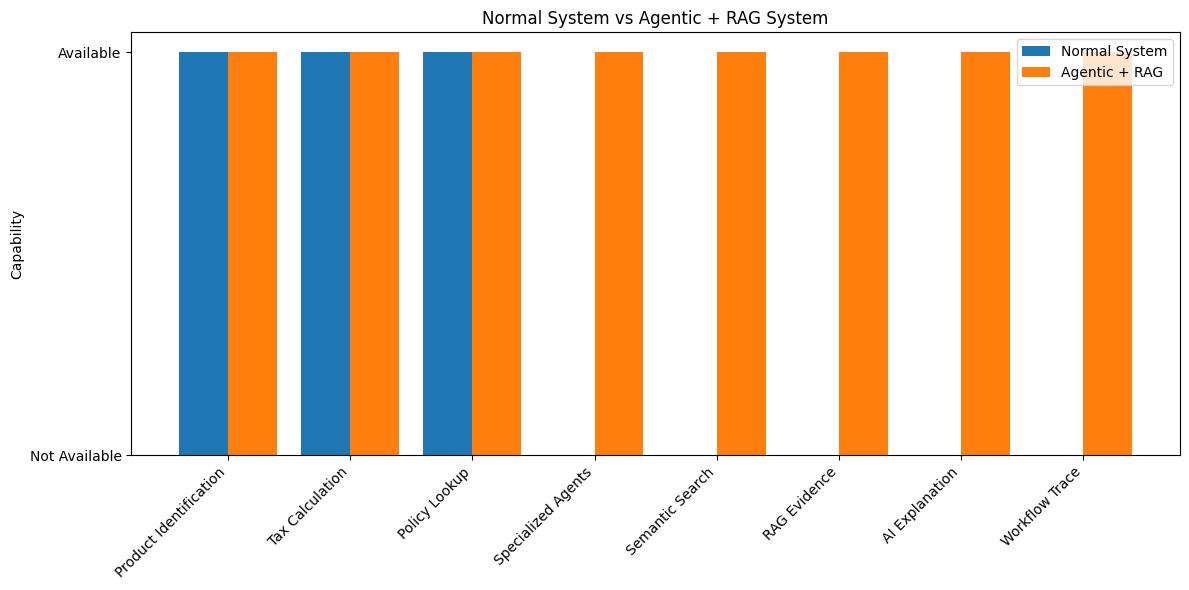

In [ ]:
import matplotlib.pyplot as plt

features = [
    "Product Identification",
    "Tax Calculation",
    "Policy Lookup",
    "Specialized Agents",
    "Semantic Search",
    "RAG Evidence",
    "AI Explanation",
    "Workflow Trace"
]

normal_system = [
    1, 1, 1, 0, 0, 0, 0, 0
]

agentic_rag_system = [
    1, 1, 1, 1, 1, 1, 1, 1
]

x = range(len(features))

plt.figure(figsize=(12, 6))

plt.bar(
    [i - 0.2 for i in x],
    normal_system,
    width=0.4,
    label="Normal System"
)

plt.bar(
    [i + 0.2 for i in x],
    agentic_rag_system,
    width=0.4,
    label="Agentic + RAG"
)

plt.xticks(x, features, rotation=45, ha="right")
plt.ylabel("Capability")
plt.title("Normal System vs Agentic + RAG System")
plt.yticks([0, 1], ["Not Available", "Available"])
plt.legend()

plt.tight_layout()
plt.show()